# Step 2 — Window-aware Feature Engineering & a Leak-free Benchmark

**Purpose.** Rebuild the interim-report features so they respect the per-type retention windows found in Step 1, then check with a simple ranker that they carry real signal once candidate position is removed.

**Design rule.** Each interaction type is only counted inside the window where it is fully recorded:

| Type | Recorded for | Used as |
|---|---|---|
| CLICK | last 7 days | `*_click_7d` |
| CART | last 90 days | `*_cart_90d` (plus `*_cart_7d` when compared with clicks) |
| ORD | last 365 days | `*_ord_365d` (plus `*_ord_90d` when compared with carts) |

Cross-type ratios are only computed inside a window that **both** types fully cover (cart:click in 7 days, order:cart in 90 days). That removes the artefact in the interim report's `hist_cart_to_click_ratio` (mean 3.76 whole-history vs 0.20 in-window).

**Inputs:** `events/candidates/users/queries.parquet` from Step 1 + `product_meta_data.txt` (category/brand IDs only).
**Output:** `features.parquet`, one row per (user, candidate), with label and split.
**Runtime:** about 10 minutes on a Colab CPU runtime (most of it is LightGBM).

In [28]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.csv as pacsv

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/JDSearch/Raw Data')
except ImportError:
    DATA_DIR = Path(os.environ.get('JD_DATA_DIR', '~/Downloads/JDsearch')).expanduser()
OUT_DIR = DATA_DIR / 'processed'

WINDOW = {0: 7, 1: 90, 2: 365}          # CLICK, CART, ORD -> days fully recorded
SEED = 42

events = pd.read_parquet(OUT_DIR / 'events.parquet')
cands = pd.read_parquet(OUT_DIR / 'candidates.parquet')
users = pd.read_parquet(OUT_DIR / 'users.parquet')
queries = pd.read_parquet(OUT_DIR / 'queries.parquet')
events = events[events['type'] < 3].reset_index(drop=True)          # follows (FLW) are <0.1% of events
nU = len(users)
print(f'events {len(events):,} | candidates {len(cands):,} | users {nU:,}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
events 26,642,681 | candidates 15,510,012 | users 173,831


## 1. Product metadata (category and brand IDs)

Only the ID columns are needed, so we read just those (a few seconds instead of loading 4.8 GB of names). Category level 2 (~670 values) and level 3 (~5,800) are used; level 3 is the closest to "the same kind of product".

In [ ]:
cols = ['wid', 'brand_id', 'cate_id_2', 'cate_id_3']
prod = pacsv.read_csv(DATA_DIR / 'product_meta_data.txt',
                      parse_options=pacsv.ParseOptions(delimiter='\t', quote_char=False),
                      convert_options=pacsv.ConvertOptions(include_columns=cols, column_types={c: pa.int64() for c in cols})
                      ).to_pandas()
prod_idx = pd.Index(prod['wid'])

def attach_meta(df):
    i = prod_idx.get_indexer(df['wid'])
    for c in ['brand_id', 'cate_id_2', 'cate_id_3']:
        df[c] = np.where(i >= 0, prod[c].to_numpy()[np.maximum(i, 0)], -1)
    return (i >= 0).mean()

print(f"metadata coverage: history {attach_meta(events):.2%} | candidates {attach_meta(cands):.2%}")
del prod, prod_idx

## 2. Helpers

Every feature is a count (or minimum age) of history events grouped by some key: (user), (user, item), (user, category), (item), and so on. It is then looked up for each candidate. `in_window` applies the per-type retention window.

In [ ]:
ev_age, ev_type, ev_user = events['age_days'].to_numpy(), events['type'].to_numpy(), events['user'].to_numpy().astype(np.int64)
in_window = ev_age < np.vectorize(WINDOW.get)(ev_type)
cand_user = cands['user'].to_numpy().astype(np.int64)
F = {}                                   # feature name -> float32 array aligned with `cands`

for col in ['wid', 'brand_id', 'cate_id_2', 'cate_id_3']:
    assert max(events[col].max(), cands[col].max()) < 2 ** 27, col

def key(user, other):                    # pack (user, id) into one int64; ids are < 2^27 and users < 2^18
    other = np.asarray(other, dtype=np.int64)
    return np.where(other >= 0, (np.asarray(user, dtype=np.int64) << 27) | (other & ((1 << 27) - 1)), -1)

def lookup(table: pd.Series, keys, fill=0.0):
    i = table.index.get_indexer(keys)
    return np.where(i >= 0, table.to_numpy()[np.maximum(i, 0)], fill).astype(np.float32)

def count_by(ev_keys, mask):
    return pd.Series(ev_keys[mask]).value_counts()

def mask(t, days=None):                  # events of type t within `days` (default: the type's full window)
    return (ev_type == t) & (ev_age < (WINDOW[t] if days is None else days))

## 3. User-level features (constant within a slate)

These describe the user rather than the candidate. Because each user has exactly one slate, they can only change the ranking **through interactions** with candidate-level features in a tree model.

In [ ]:
def per_user(m):
    return np.bincount(ev_user[m], minlength=nU).astype(np.float32)

U = pd.DataFrame({'user': np.arange(nU)})
for t, name in [(0, 'click'), (1, 'cart'), (2, 'ord')]:
    U[f'u_{name}_{WINDOW[t]}d'] = per_user(mask(t))
U['u_cart_7d'], U['u_ord_7d'], U['u_ord_90d'] = per_user(mask(1, 7)), per_user(mask(2, 7)), per_user(mask(2, 90))

# in-window conversion ratios, shrunk toward the global ratio for users with few events
def shrunk_ratio(num, den, alpha=5.0):
    p = num.sum() / den.sum()
    return ((num + alpha * p) / (den + alpha)).astype(np.float32), p
U['u_cart_per_click_7d'], p1 = shrunk_ratio(U['u_cart_7d'], U['u_click_7d'])
U['u_ord_per_cart_90d'], p2 = shrunk_ratio(U['u_ord_90d'], U['u_cart_90d'])
print(f'global in-window rates: carts per click (7d) = {p1:.3f}, orders per cart (90d) = {p2:.3f}')

for t, name in [(0, 'click'), (1, 'cart'), (2, 'ord')]:        # recency of each type; NaN = none in window
    m = mask(t)
    U[f'u_days_since_{name}'] = pd.Series(ev_age[m]).groupby(ev_user[m]).min().reindex(range(nU)).to_numpy(np.float32)

q_less = (events['qry'].to_numpy() == -1)
m7 = in_window & (ev_age < 7)
U['u_queryless_share_7d'] = (np.bincount(ev_user[m7 & q_less], minlength=nU) / np.maximum(np.bincount(ev_user[m7], minlength=nU), 1)).astype(np.float32)

real_q = events.loc[events['qry'] >= 0, ['user', 'qry']]
nq = real_q.groupby('user')['qry'].agg(['size', 'nunique']).reindex(range(nU)).fillna(0)
U['u_n_distinct_queries'] = nq['nunique'].to_numpy(np.float32)
U['u_query_repeat_rate'] = (1 - nq['nunique'] / nq['size'].clip(lower=1)).to_numpy(np.float32)     # real queries only, no '-1'

## 4. Query features

The test query never repeats verbatim in a user's history (1 of 173,831), so the interim report's `query_in_history` is replaced by **term overlap**. We also add a **query→category prior** learned from all users' search-linked history: how often a past search containing each term led to an interaction in the candidate's level-3 category. It is a cheap relevance signal that also works for cold products (80% of candidates never appear in any history).

In [ ]:
terms = queries.set_index('qry')['text'].str.split('\x18')
q_terms = users['qry'].map(terms)
U['q_n_terms'] = q_terms.str.len().to_numpy(np.float32)

hist_q = real_q.drop_duplicates()
hist_terms = hist_q.assign(t=hist_q['qry'].map(terms)).explode('t').groupby('user')['t'].agg(set)
U['q_term_overlap'] = np.array([len(set(q) & hist_terms.get(u, set())) / len(q)
                                for u, q in zip(users['user'], q_terms)], dtype=np.float32)
del hist_terms

# term -> cate_id_3 counts from search-linked history events (all users, all types in window)
term_codes, term_vocab = pd.factorize(pd.Series([t for ts in terms.to_numpy() for t in ts]).unique())
term_id = pd.Series(np.arange(len(term_vocab)), index=term_vocab)
c3_codes, c3_vocab = pd.factorize(np.concatenate([events['cate_id_3'].to_numpy(), cands['cate_id_3'].to_numpy()]))
n_c3 = len(c3_vocab)
ev_c3, cand_c3 = c3_codes[:len(events)], c3_codes[len(events):]

sl = (events['qry'].to_numpy() >= 0) & in_window & (events['cate_id_3'].to_numpy() >= 0)
qc = pd.DataFrame({'qry': events['qry'].to_numpy()[sl], 'c3': ev_c3[sl]}).value_counts().rename('n').reset_index()
qc['t'] = qc['qry'].map(terms)
qc = qc.explode('t')
qc['t'] = term_id.reindex(qc['t']).to_numpy()
tc = qc.groupby(['t', 'c3'])['n'].sum()
term_total = tc.groupby(level=0).sum()
p_c3_given_t = (tc / (term_total.reindex(tc.index.get_level_values(0)).to_numpy() + 10.0))   # smoothed P(c3 | term)
p_c3_given_t.index = p_c3_given_t.index.get_level_values(0).astype(np.int64) * n_c3 + p_c3_given_t.index.get_level_values(1)
del qc, tc

# score each candidate: mean and max over the test-query terms of P(candidate's c3 | term)
qt = q_terms.explode().to_frame('t')                                  # index = user id
qt['tid'] = term_id.reindex(qt['t']).to_numpy()
qt['j'] = qt.groupby(level=0).cumcount()
q_term_pad = np.full((nU, qt['j'].max() + 1), -1, np.int64)          # user x term slot, -1 = no term
q_term_pad[qt.index.to_numpy(), qt['j'].to_numpy()] = qt['tid'].to_numpy()
acc_sum = np.zeros(len(cands), np.float32); acc_max = np.zeros(len(cands), np.float32)
n_terms_cand = U['q_n_terms'].to_numpy()[cand_user]
for j in range(q_term_pad.shape[1]):
    tj = q_term_pad[cand_user, j]
    k = np.where((tj >= 0) & (cand_c3 >= 0), tj * n_c3 + cand_c3, -1)
    v = lookup(p_c3_given_t, k)
    acc_sum += v; acc_max = np.maximum(acc_max, v)
F['qc_cat3_prior_mean'] = acc_sum / np.maximum(n_terms_cand, 1)
F['qc_cat3_prior_max'] = acc_max
del p_c3_given_t, acc_sum, acc_max
print('query features done')

## 5. User × candidate features (personal history with this item, brand and category)

In [ ]:
ck_item = key(cand_user, cands['wid'])
ek_item = key(ev_user, events['wid'])
for t, name in [(0, 'click'), (1, 'cart'), (2, 'ord')]:
    F[f'uc_{name}_{WINDOW[t]}d'] = lookup(count_by(ek_item, mask(t)), ck_item)
age_item = pd.Series(ev_age[in_window]).groupby(ek_item[in_window]).min()
F['uc_days_since_any'] = lookup(age_item, ck_item, fill=np.nan)            # NaN = never interacted

for level, col in [('brand', 'brand_id'), ('cat3', 'cate_id_3'), ('cat2', 'cate_id_2')]:
    ek, ck = key(ev_user, events[col]), key(cand_user, cands[col])
    for t, name in [(0, 'click'), (1, 'cart'), (2, 'ord')]:
        F[f'u{level}_{name}_{WINDOW[t]}d'] = lookup(count_by(ek, mask(t) & (ek >= 0)), ck)
    F[f'u{level}_days_since_any'] = lookup(pd.Series(ev_age[in_window]).groupby(ek[in_window]).min(), ck, fill=np.nan)
print('user x candidate features done')

## 6. Item- and category-level features (popularity among *other* users)

- **Item popularity** = number of *distinct other users* who interacted with the item, per type and window. The focal user is left out because their own history is already covered above. This replaces `product_velocity_30d_decay` and the 24-hour velocity features, which summed all types over one window even though clicks only exist for 7 days.
- **Category conversion rates** are computed inside shared windows only, replacing `category_*_ratio`.

In [ ]:
cand_wid = cands['wid'].to_numpy()
for t, name in [(0, 'click'), (1, 'cart'), (2, 'ord')]:
    m = mask(t)
    pairs = pd.DataFrame({'u': ev_user[m], 'w': events['wid'].to_numpy()[m]}).drop_duplicates()
    n_users = pairs['w'].value_counts()
    own = (F[f'uc_{name}_{WINDOW[t]}d'] > 0).astype(np.float32)
    F[f'i_users_{name}_{WINDOW[t]}d'] = lookup(n_users, cand_wid) - own

c3 = pd.Series(ev_c3)
cat_click7 = c3[mask(0)].value_counts(); cat_cart7 = c3[mask(1, 7)].value_counts()
cat_cart90 = c3[mask(1)].value_counts(); cat_ord90 = c3[mask(2, 90)].value_counts()
F['c3_click_7d'] = lookup(cat_click7, cand_c3)
F['c3_cart_per_click_7d'] = (lookup(cat_cart7, cand_c3) + 5 * p1) / (F['c3_click_7d'] + 5)
F['c3_ord_per_cart_90d'] = (lookup(cat_ord90, cand_c3) + 5 * p2) / (lookup(cat_cart90, cand_c3) + 5)

# slate context: how much of this slate shares the candidate's category (known at ranking time, no labels used)
grp = pd.Series(key(cand_user, cand_c3))
F['slate_cat3_share'] = (grp.map(grp.value_counts()).to_numpy() / users['n_cand'].to_numpy()[cand_user]).astype(np.float32)
F['slate_len'] = users['n_cand'].to_numpy()[cand_user].astype(np.float32)
print('item / category features done')

## 7. Assemble the feature table and split by user

Splits are made **by user** (each user = one slate): 70% train, 15% validation, 15% test. Candidate position is **not** a feature, and evaluation breaks score ties at random so list order can't leak in.

In [21]:
import gc
del events, ev_age, ev_type, ev_user, in_window, ek_item, age_item, pairs, grp, c3, q_less, real_q, hist_q
gc.collect()

feat = pd.DataFrame(F); del F
for c in U.columns.drop('user'):
    feat[c] = U[c].to_numpy()[cand_user]
feat.insert(0, 'user', cands['user'].to_numpy())
feat.insert(1, 'wid', cand_wid)
feat.insert(2, 'label', cands['label'].to_numpy())

rng = np.random.default_rng(SEED)
split_of_user = rng.choice(np.array(['train', 'val', 'test']), size=nU, p=[0.70, 0.15, 0.15])
feat['split'] = split_of_user[cand_user]
FEATURES = [c for c in feat.columns if c not in ('user', 'wid', 'label', 'split')]
print(f'{len(FEATURES)} features | rows {len(feat):,} | memory {feat.memory_usage().sum() / 1e9:.1f} GB')
feat.to_parquet(OUT_DIR / 'features.parquet', index=False)
print('saved', OUT_DIR / 'features.parquet')

42 features | rows 15,510,012 | memory 2.9 GB
saved /content/drive/MyDrive/JDSearch/Raw Data/processed/features.parquet


In [22]:
desc = feat[FEATURES].describe(percentiles=[0.5]).T[['count', 'min', 'max', 'mean', '50%', 'std']]
desc['missing'] = feat[FEATURES].isna().sum()
desc.round(3)

,count,min,max,mean,50%,std,missing
qc_cat3_prior_mean,15510012.0,0.000,0.994,0.301,0.234,0.271,0
qc_cat3_prior_max,15510012.0,0.000,0.994,0.460,0.462,0.341,0
uc_click_7d,15510012.0,0.000,176.000,0.014,0.000,0.335,0
uc_cart_90d,15510012.0,0.000,73.000,0.004,0.000,0.105,0
uc_ord_365d,15510012.0,0.000,57.000,0.001,0.000,0.053,0
uc_days_since_any,121695.0,0.000,364.381,17.676,0.608,48.963,15388317
ubrand_click_7d,15510012.0,0.000,1057.000,1.377,0.000,9.047,0
ubrand_cart_90d,15510012.0,0.000,1206.000,0.831,0.000,5.803,0
ubrand_ord_365d,15510012.0,0.000,646.000,0.152,0.000,1.721,0
ubrand_days_since_any,3487166.0,0.000,364.828,21.219,0.722,53.272,12022846


## 8. Evaluation helpers

- **NDCG@10** uses gain 2^label − 1, so a purchase counts more than a cart, and a cart more than a click (the ordinal target).
- **HR@10** = share of slates with any interaction in the top 10.
- **Purchase-HR@10** = share of slates *containing a purchase* that rank it in the top 10, closest to the business goal of session conversion.
- Only slates with at least one interaction are scored (171,728 of 173,831).

In [23]:
def evaluate(df, score, k=10, seed=0):
    """Vectorised per-slate ranking metrics with random tie-breaking."""
    u = df['user'].to_numpy(); lab = df['label'].to_numpy().astype(np.float64)
    r = np.random.default_rng(seed).random(len(df))
    order = np.lexsort((r, -np.asarray(score, dtype=np.float64), u))
    u_s, lab_s = u[order], lab[order]
    start = np.r_[0, np.flatnonzero(u_s[1:] != u_s[:-1]) + 1]
    rank = np.arange(len(u_s)) - np.repeat(start, np.diff(np.r_[start, len(u_s)]))
    top = rank < k
    disc = np.where(top, 1.0 / np.log2(rank + 2), 0.0)
    gid = np.repeat(np.arange(len(start)), np.diff(np.r_[start, len(u_s)]))
    dcg = np.bincount(gid, weights=(2 ** lab_s - 1) * disc)
    ideal_order = np.lexsort((-lab, u)); lab_i = lab[ideal_order]
    idcg = np.bincount(gid, weights=(2 ** lab_i - 1) * disc)          # same group layout: sorted by user
    has_pos = np.bincount(gid, weights=(lab_s > 0)) > 0
    has_buy = np.bincount(gid, weights=(lab_s == 3)) > 0
    hit = np.bincount(gid, weights=(lab_s > 0) & top) > 0
    hit_buy = np.bincount(gid, weights=(lab_s == 3) & top) > 0
    return {'NDCG@10': (dcg[has_pos] / idcg[has_pos]).mean(), 'HR@10': hit[has_pos].mean(),
            'Purchase-HR@10': hit_buy[has_buy].mean(), 'slates': int(has_pos.sum())}

val = feat[feat['split'] == 'val']
single = pd.DataFrame({f: evaluate(val, val[f].fillna(-1e9) if 'days_since' not in f else -val[f].fillna(1e9))
                       for f in FEATURES}).T                       # recency: fewer days = better
single.loc['random'] = evaluate(val, np.zeros(len(val)))
single.sort_values('NDCG@10', ascending=False).round(4).head(20)

,NDCG@10,HR@10,Purchase-HR@10,slates
i_users_cart_90d,0.3330,0.6277,0.5665,25825.0
i_users_click_7d,0.3285,0.6228,0.5524,25825.0
i_users_ord_365d,0.2875,0.5605,0.5465,25825.0
uc_days_since_any,0.1802,0.3447,0.2601,25825.0
uc_click_7d,0.1556,0.3148,0.2095,25825.0
uc_cart_90d,0.1260,0.2797,0.2102,25825.0
ubrand_days_since_any,0.1206,0.3027,0.2489,25825.0
ubrand_click_7d,0.1131,0.2844,0.2072,25825.0
ubrand_cart_90d,0.1049,0.2721,0.2108,25825.0
qc_cat3_prior_mean,0.1010,0.2643,0.1747,25825.0


Each feature above is used **alone** as a ranker on the validation slates. User-level features (`u_*`, `q_*`) score exactly like random because they are constant within a slate, as expected. The strongest single signals are the user's own history with the item, brand and category, and the query→category prior.

## 9. A first leak-free benchmark: LightGBM LambdaRank

This is not the final model; it is a sanity check that the window-aware features carry signal without position leakage. Rows are shuffled within each slate before training so LightGBM's internal tie handling can't pick up list order.

In [24]:
import lightgbm as lgb, warnings
warnings.filterwarnings('ignore', category=lgb.basic.LGBMDeprecationWarning) if hasattr(lgb.basic, 'LGBMDeprecationWarning') else None
warnings.filterwarnings('ignore', message='.*eval_set.*deprecated')

def prepared(split):
    d = feat[feat['split'] == split]
    d = d.iloc[np.lexsort((np.random.default_rng(SEED).random(len(d)), d['user'].to_numpy()))]   # shuffle within slate
    d = d[d.groupby('user')['label'].transform('max') > 0]                                        # slates with a positive
    return d, d.groupby('user', sort=False).size().to_numpy()

tr, g_tr = prepared('train'); va, g_va = prepared('val'); te, _ = prepared('test')
del feat, val; gc.collect()

def fit(cols, n_estimators=600):
    m = lgb.LGBMRanker(objective='lambdarank', n_estimators=n_estimators, learning_rate=0.05, num_leaves=63,
                       min_child_samples=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=SEED, n_jobs=-1, verbose=-1)
    m.fit(tr[cols], tr['label'], group=g_tr, eval_set=[(va[cols], va['label'])], eval_group=[g_va],
          eval_at=[10], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

t0 = time.time()
model = fit(FEATURES)
print(f'trained in {time.time() - t0:.0f}s, best iteration {model.best_iteration_}')

results = pd.DataFrame({
    'random': evaluate(te, np.zeros(len(te))),
    'item popularity only (i_users_ord_365d)': evaluate(te, te['i_users_ord_365d']),
    'LightGBM, all window-aware features (train)': evaluate(tr, model.predict(tr[FEATURES])),
    'LightGBM, all window-aware features (test)': evaluate(te, model.predict(te[FEATURES])),
}).T
results.round(4)

trained in 194s, best iteration 320


,NDCG@10,HR@10,Purchase-HR@10,slates
random,0.0839,0.2268,0.1371,25822.0
item popularity only (i_users_ord_365d),0.2916,0.5660,0.5642,25822.0
"LightGBM, all window-aware features (train)",0.4207,0.7148,0.6562,120081.0
"LightGBM, all window-aware features (test)",0.4075,0.7046,0.6633,25822.0


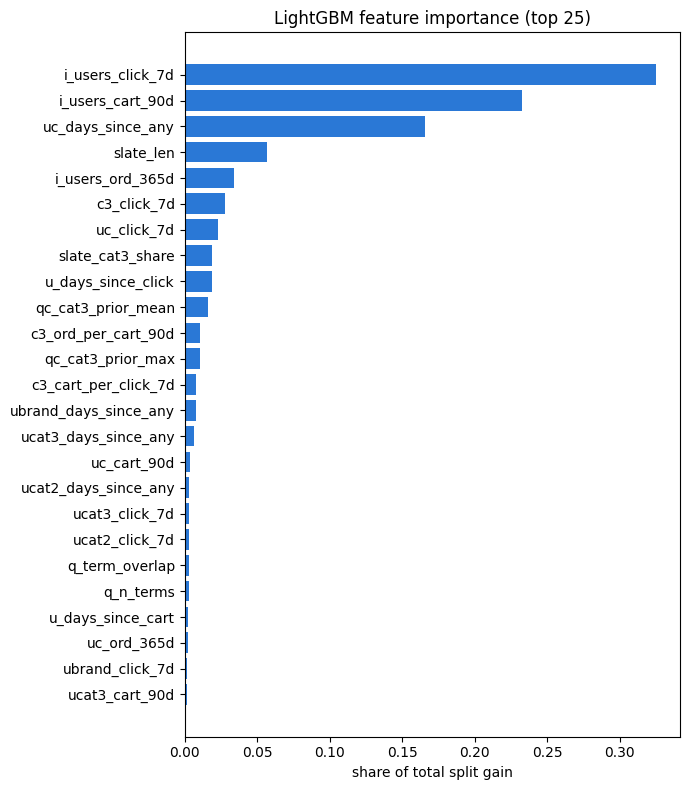

In [25]:
imp = pd.Series(model.booster_.feature_importance('gain'), index=FEATURES).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(imp.index[-25:], imp.values[-25:], color='#2a78d6')
ax.set_xlabel('share of total split gain'); ax.set_title('LightGBM feature importance (top 25)')
plt.tight_layout(); plt.show()

### Feature-group ablation (test set)

Each feature group is dropped in turn and the model retrained, which shows which groups the model actually depends on.

In [26]:
groups = {
    'user x item (uc_*)': [f for f in FEATURES if f.startswith('uc_')],
    'user x brand/category (ubrand/ucat*)': [f for f in FEATURES if f.startswith(('ubrand_', 'ucat'))],
    'query (q_*, qc_*)': [f for f in FEATURES if f.startswith(('q_', 'qc_'))],
    'item popularity (i_*)': [f for f in FEATURES if f.startswith('i_')],
    'category & slate (c3_*, slate_*)': [f for f in FEATURES if f.startswith(('c3_', 'slate_'))],
    'user-level (u_*)': [f for f in FEATURES if f.startswith('u_')],
}
base = evaluate(te, model.predict(te[FEATURES]))
rows = []
for gname, cols in groups.items():
    keep = [f for f in FEATURES if f not in cols]
    m = fit(keep, n_estimators=300)
    r = evaluate(te, m.predict(te[keep]))
    rows.append({'dropped group': gname, 'n features': len(cols), **{k: r[k] - base[k] for k in ('NDCG@10', 'HR@10', 'Purchase-HR@10')}})
pd.DataFrame(rows).set_index('dropped group').round(4)

,n features,NDCG@10,HR@10,Purchase-HR@10
dropped group,,,,
user x item (uc_*),4,-0.0344,-0.0234,-0.0191
user x brand/category (ubrand/ucat*),12,-0.0038,-0.0054,-0.0075
"query (q_*, qc_*)",4,0.0001,0.0002,0.0006
item popularity (i_*),3,-0.2022,-0.3128,-0.3574
"category & slate (c3_*, slate_*)",5,-0.0020,-0.0020,-0.0019
user-level (u_*),14,-0.0001,-0.0005,-0.0016


### Leakage check on item popularity

All test queries were issued on the same day (2022-10-17), so another user's history from that day could, in principle, include events that happened *after* this user's query. If popularity were leaking, dropping each user's most recent day of events would hurt it noticeably.

In [27]:
ev = pd.read_parquet(OUT_DIR / 'events.parquet', columns=['user', 'wid', 'type', 'age_days'])
rows = {}
for lo in [0, 1, 2]:
    m = (ev['type'] == 1) & (ev['age_days'] < 90) & (ev['age_days'] >= lo)
    n_users = ev.loc[m, ['user', 'wid']].drop_duplicates()['wid'].value_counts()
    rows[f'cart popularity using events older than {lo} d'] = evaluate(te, te['wid'].map(n_users).fillna(0).to_numpy())
del ev
pd.DataFrame(rows).T.round(4)

,NDCG@10,HR@10,Purchase-HR@10,slates
cart popularity using events older than 0 d,0.3387,0.6387,0.5962,25822.0
cart popularity using events older than 1 d,0.3351,0.6338,0.5881,25822.0
cart popularity using events older than 2 d,0.3339,0.6315,0.5862,25822.0


## 10. Takeaways for the modelling phase

- **The benchmark is leak-free and reasonably strong.** Test NDCG@10 ≈ 0.41 vs 0.08 random, with train ≈ test. Compare this with the position-only "model" in the interim report (NDCG@10 = 0.98), which was pure leakage.
- **Item popularity (other users, in-window) carries most of the signal.** Dropping it costs ~0.20 NDCG@10, and the check above shows it isn't same-day leakage. The NCF/NMF baselines should be compared against this popularity ranker, not just against random.
- **The user's own history with the item comes next** (−0.03 NDCG@10 when removed), followed by brand/category affinity.
- **User-level features add nothing on their own** (constant within a slate), as expected. They are kept for interaction effects in later neural models and for segment-level error analysis (e.g. users with no clicks in 7 days = 16%).
- **The query features don't help yet.** The category prior is too coarse. Real query→product text relevance (the team's TF-IDF similarity on product names, or embeddings) is the main gap to close next, which matters most for the ~80% of candidates that are cold items.